In [1]:

import sys
from pathlib import Path
from beir import util
from beir.datasets.data_loader import GenericDataLoader

PHAN_B_DIR = Path.cwd().resolve()
ROOT_DIR = PHAN_B_DIR.parent
DATA_DIR = PHAN_B_DIR / "du_lieu"

sys.path.insert(0, str(ROOT_DIR))

from bm25 import ChiMuc


d:\RAG\tep_kem\.venv\Lib\site-packages\beir\util.py:11: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


In [2]:

dataset = "nfcorpus"
url = f"https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/{dataset}.zip"

dataset_path = DATA_DIR / dataset

if not dataset_path.exists():
    util.download_and_unzip(url, str(DATA_DIR))

corpus, queries, qrels = GenericDataLoader(
    data_folder=str(dataset_path)
).load(split="test")

print("Số tài liệu:", len(corpus))
print("Số truy vấn:", len(queries))
print("Số truy vấn có nhãn:", len(qrels))


D:\RAG\tep_kem\phanB\du_lieu\nfcorpus.zip: 100%|██████████| 2.34M/2.34M [00:01<00:00, 1.40MiB/s]
100%|██████████| 3633/3633 [00:00<00:00, 199449.04it/s]

Số tài liệu: 3633
Số truy vấn: 323
Số truy vấn có nhãn: 323



### 2. Kiểm tra phân bố nhãn liên quan (qrels)

Trước khi đánh giá chất lượng truy xuất, tiến hành thống kê phân bố các mức nhãn liên quan trong tập test NFCorpus.

**Kết quả thống kê:**

| Mức nhãn | Số lượng | Tỷ lệ |
|---|---:|---:|
| 1 | 11.758 | 95,33% |
| 2 | 576 | 4,67% |
| **Tổng** | **12.334** | **100%** |

**Thang nhãn sử dụng:**
- **0:** Không liên quan (quy ước cho tài liệu không có trong qrels).
- **1:** Mức liên quan thấp hơn.
- **2:** Mức liên quan cao hơn.

**Nhận xét:**

- NFCorpus có 12.334 phán định liên quan trên 323 truy vấn test.
- Nhãn 1 chiếm đa số (95,33%), trong khi nhãn 2 chỉ chiếm 4,67%.
- NFCorpus sử dụng nhãn liên quan nhiều mức, do đó khi tính nDCG@10, xếp hạng lý tưởng cần ưu tiên tài liệu có nhãn 2 trước nhãn 1.
- Việc thống kê nhãn được thực hiện trước khi tính các chỉ số đánh giá, theo yêu cầu của bài thực hành.


In [ ]:
from collections import Counter

phan_bo_nhan = Counter()

for nhan_truy_van in qrels.values():
    phan_bo_nhan.update(nhan_truy_van.values())

print("Phân bố nhãn liên quan trong NFCorpus:")

for muc_nhan, so_luong in sorted(phan_bo_nhan.items()):
    print(f"Nhãn {muc_nhan}: {so_luong}")

print("Tổng số phán định:", sum(phan_bo_nhan.values()))


Phân bố nhãn liên quan trong NFCorpus:
Nhãn 1: 11758
Nhãn 2: 576
Tổng số phán định: 12334



### Cấu trúc dữ liệu NFCorpus

| Biến | Cấu trúc | Nội dung |
|---|---|---|
| `corpus` | `dict[str, dict]` | Mã tài liệu → tiêu đề, nội dung, metadata |
| `queries` | `dict[str, str]` | Mã truy vấn → nội dung truy vấn |
| `qrels` | `dict[str, dict]` | Mã truy vấn → `{mã tài liệu: mức liên quan}` |


In [9]:
from pprint import pprint

corpus_iter = iter(corpus.items())
queries_iter = iter(queries.items())
qrels_iter = iter(qrels.items())

# Lấy phần tử đầu tiên
doc_id, doc = next(corpus_iter)
query_id, query_text = next(queries_iter)
qrel_query_id, relevance = next(qrels_iter)

print("=== 1. CORPUS ===")
print("Document ID:", doc_id)
pprint(doc)

print("\n=== 2. QUERIES ===")
print("Query ID:", query_id)
print("Query text:", query_text)

print("\n=== 3. QRELS ===")
print("Query ID:", qrel_query_id)
pprint(relevance)

=== 1. CORPUS ===
Document ID: MED-10
{'text': 'Recent studies have suggested that statins, an established drug '
         'group in the prevention of cardiovascular mortality, could delay or '
         'prevent breast cancer recurrence but the effect on disease-specific '
         'mortality remains unclear. We evaluated risk of breast cancer death '
         'among statin users in a population-based cohort of breast cancer '
         'patients. The study cohort included all newly diagnosed breast '
         'cancer patients in Finland during 1995–2003 (31,236 cases), '
         'identified from the Finnish Cancer Registry. Information on statin '
         'use before and after the diagnosis was obtained from a national '
         'prescription database. We used the Cox proportional hazards '
         'regression method to estimate mortality among statin users with '
         'statin use as time-dependent variable. A total of 4,151 participants '
         'had used statins. During the


### 3. Xây dựng chỉ mục BM25

Sử dụng lớp `ChiMuc` đã cài đặt ở Phần A để xây dựng chỉ mục cho 3.633 tài liệu NFCorpus.

Mỗi tài liệu được biểu diễn bằng cách ghép tiêu đề (`title`) và nội dung (`text`). Văn bản được tách token bằng phương pháp khoảng trắng.

Sau khi xây dựng chỉ mục, thống kê:
- Tổng số tài liệu (N).
- Độ dài trung bình của tài liệu (avgdl).
- Số token phân biệt trong kho.


In [8]:
kho = {
    doc_id: doc["title"] + " " + doc["text"]
    for doc_id, doc in corpus.items()
}

chi_muc = ChiMuc(kho)

print("Số tài liệu:", chi_muc.n)
print("Độ dài trung bình:", chi_muc.avgdl)
print("Số token khác nhau:", len(chi_muc.chi_muc))

Số tài liệu: 3633
Độ dài trung bình: 233.76520781723093
Số token khác nhau: 66399



### 4. Truy xuất BM25 trên toàn bộ truy vấn NFCorpus

Sử dụng chỉ mục BM25 tự cài đặt để truy xuất tài liệu cho 323 truy vấn thuộc tập test NFCorpus.

Cấu hình thực nghiệm:
- `k1 = 1.2`
- `b = 0.75`
- `top_k = 100`
- Tokenizer: tách từ theo khoảng trắng.

Kết quả truy xuất được lưu theo mã truy vấn, trong đó mỗi truy vấn chứa danh sách mã tài liệu và điểm BM25 tương ứng, theo thứ tự giảm dần của điểm số.


In [ ]:
ket_qua_bm25 = {}

for query_id, query_text in queries.items():
    danh_sach = chi_muc.tim(query_text, k=100, k1=1.2, b=0.75)

    ket_qua_bm25[query_id] = {
        doc_id: score
        for doc_id, score in danh_sach
    }
    '''
        {
            "query_id": {
                "doc_id": score
            }
        }
    '''
print("Số truy vấn đã xử lý:", len(ket_qua_bm25))

query_id = next(iter(ket_qua_bm25))

print("Query ID:", query_id)
print("Số tài liệu truy xuất:", len(ket_qua_bm25[query_id]))

print("Rank", "Doc ID", "BM25 Score", sep="\t")

for rank, (doc_id, score) in enumerate(
    list(ket_qua_bm25[query_id].items())[:5], start=1
):
    print(rank, doc_id, round(score, 4), sep="\t")

Số truy vấn đã xử lý: 323
Query ID: PLAIN-2
Số tài liệu truy xuất: 100
Rank	Doc ID	BM25 Score
1	MED-2429	17.6137
2	MED-10	15.4508
3	MED-14	14.4329
4	MED-1193	14.2964
5	MED-2431	14.1519



### 5. Đánh giá chất lượng truy xuất BM25 trên NFCorpus

Đánh giá kết quả truy xuất của 323 truy vấn NFCorpus bằng các hàm tự cài đặt trong `chi_so.py`.

Các chỉ số:
- **nDCG@10:** Chất lượng xếp hạng trong top 10, sử dụng nhãn liên quan nhiều mức.
- **Recall@100:** Tỷ lệ tài liệu liên quan được tìm thấy trong top 100.
- **MRR@100:** Trung bình nghịch đảo thứ hạng của tài liệu liên quan đầu tiên.
- **MAP@100:** Trung bình Average Precision trên danh sách top 100.

Các chỉ số được tính cho từng truy vấn và lấy trung bình trên toàn bộ 323 truy vấn.


In [11]:
from chi_so import (
    ndcg_at_k,
    recall_at_k,
    reciprocal_rank,
    average_precision
)

tong_ndcg = 0.0
tong_recall = 0.0
tong_rr = 0.0
tong_ap = 0.0

for query_id, ket_qua in ket_qua_bm25.items():
    thu_hang = list(ket_qua.keys())
    nhan_lien_quan = qrels[query_id]

    tong_ndcg += ndcg_at_k(thu_hang, nhan_lien_quan, 10)
    tong_recall += recall_at_k(thu_hang, nhan_lien_quan, 100)
    tong_rr += reciprocal_rank(thu_hang, nhan_lien_quan)
    tong_ap += average_precision(thu_hang, nhan_lien_quan)

so_truy_van = len(ket_qua_bm25)

print("=== KẾT QUẢ BM25 TRÊN NFCORPUS ===")
print("nDCG@10:", round(tong_ndcg / so_truy_van, 4))
print("Recall@100:", round(tong_recall / so_truy_van, 4))
print("MRR@100:", round(tong_rr / so_truy_van, 4))
print("MAP@100:", round(tong_ap / so_truy_van, 4))

=== KẾT QUẢ BM25 TRÊN NFCORPUS ===
nDCG@10: 0.2697
Recall@100: 0.2064
MRR@100: 0.4828
MAP@100: 0.1155



### 5.1. Kết quả đánh giá và nhận xét

BM25 tự cài đặt được đánh giá trên 323 truy vấn NFCorpus với cấu hình `k1 = 1.2`, `b = 0.75`, sử dụng tokenizer tách khoảng trắng và truy xuất tối đa 100 tài liệu cho mỗi truy vấn.

| Chỉ số | Kết quả |
|---|---:|
| nDCG@10 | 0.2697 |
| Recall@100 | 0.2064 |
| MRR@100 | 0.4828 |
| MAP@100 | 0.1155 |

**Nhận xét:**

- nDCG@10 đạt 0.2697, phản ánh chất lượng xếp hạng trong top 10 còn hạn chế.
- Recall@100 đạt 0.2064, cho thấy hệ thống chỉ tìm được trung bình khoảng 20,64% tài liệu liên quan.
- MRR@100 đạt 0.4828, cho thấy hệ thống vẫn có khả năng đưa tài liệu liên quan đầu tiên lên vị trí cao.
- MAP@100 đạt 0.1155, phản ánh khả năng truy xuất và xếp hạng toàn bộ tài liệu liên quan chưa cao.

So với SciFact, NFCorpus có điểm thấp hơn ở cả bốn chỉ số. Tuy nhiên, hai bộ dữ liệu khác nhau về số lượng tài liệu liên quan và thang nhãn, nên cần tiếp tục so sánh với hệ thống BM25 chuẩn trước khi đưa ra kết luận về hiệu quả thuật toán.


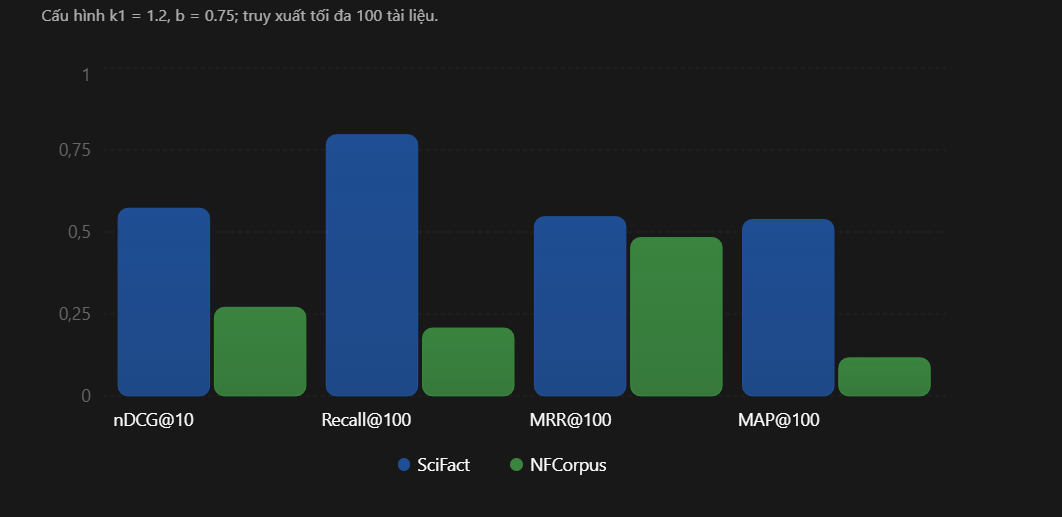